# Task 5: Exploratory Data Analysis (EDA)

## Titanic Dataset

### Data Analyst Internship

**Objective:** Extract insights using visual and statistical exploration.

**Tools Used:**
- Python
- Pandas
- Matplotlib
- Seaborn

**Dataset:** Titanic Dataset

In [2]:
#Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_theme(style="whitegrid")

In [3]:
#Load the dataset
df = pd.read_csv("train.csv")

## 1. Loading and Understanding the Dataset

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
#Displaying last 5 rows
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [6]:
#Checking dataset size
df.shape

(891, 12)

In [7]:
#Checking column names
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [8]:
#Checking datatypes
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

## 2. Dataset Information

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


## 3. Missing Value Analysis

In [10]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [11]:
#Finding missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage.sort_values(ascending=False)

Cabin          77.104377
Age            19.865320
Embarked        0.224467
PassengerId     0.000000
Name            0.000000
Pclass          0.000000
Survived        0.000000
Sex             0.000000
Parch           0.000000
SibSp           0.000000
Fare            0.000000
Ticket          0.000000
dtype: float64

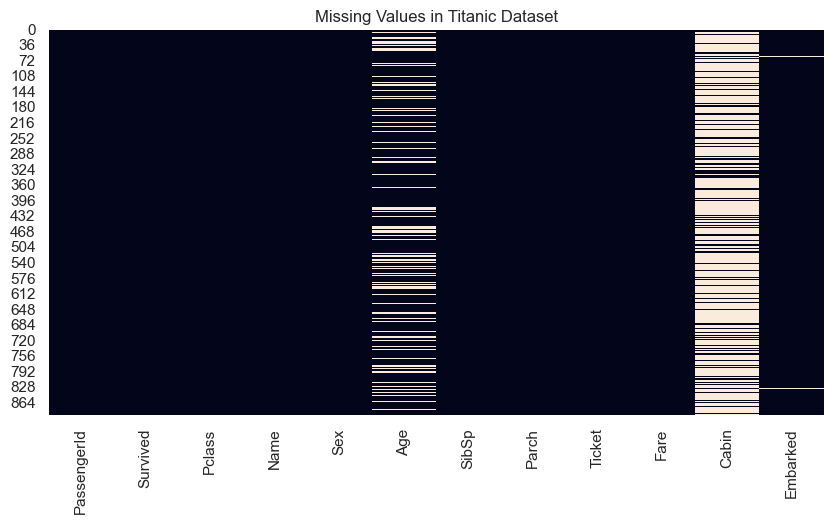

In [12]:
#Visualizing missing values
plt.figure(figsize=(10, 5))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values in Titanic Dataset")
plt.show()

### Observation

The missing-value heatmap shows which columns contain missing observations.
Columns with a higher concentration of missing values require further consideration
during data preprocessing.

## 4. Descriptive Statistical Analysis

In [13]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [14]:
#Describing categorical data
df.describe(include="object")

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


## 5. Categorical Variable Analysis

In [15]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

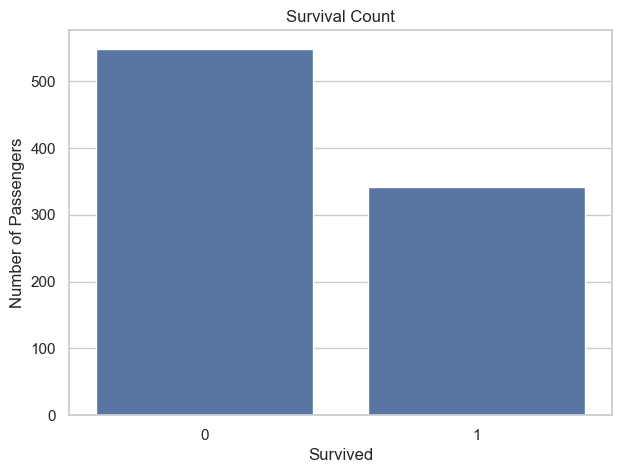

In [16]:
#Survival Count Plot
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Survived")

plt.title("Survival Count")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")

plt.show()

### Observation

The count plot compares passengers who survived with those who did not survive.
The two categories have noticeably different passenger counts.

In [17]:
#Analyzing Gender
df["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

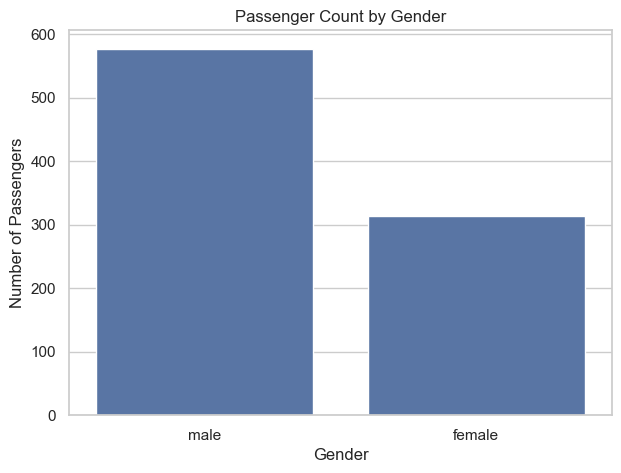

In [18]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Sex")

plt.title("Passenger Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

### Observation

The plot shows the distribution of male and female passengers in the Titanic dataset.

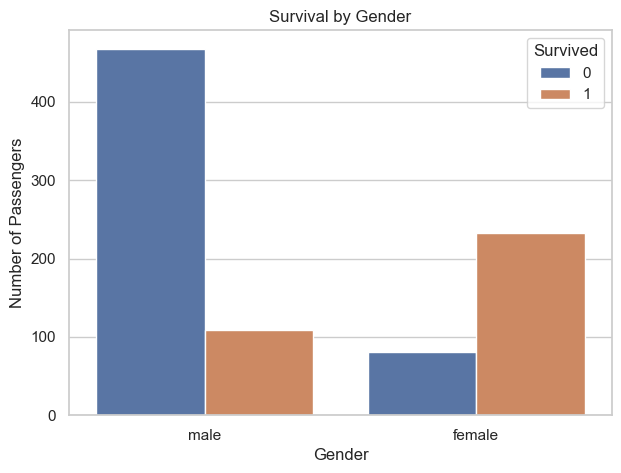

In [19]:
#Survival by gender
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Sex", hue="Survived")

plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

### Observation

Survival outcomes differ substantially between male and female passengers.
The visualization indicates a strong relationship between gender and survival.

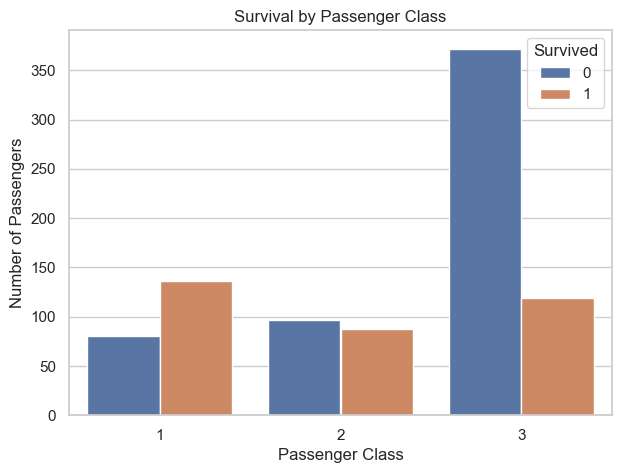

In [20]:
#Survival By Passenger Class
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Pclass", hue="Survived")

plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()

### Observation

Survival outcomes vary across passenger classes. Passengers belonging to
different classes experienced different survival patterns.

In [21]:
#Analyzing Age
df["Age"].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

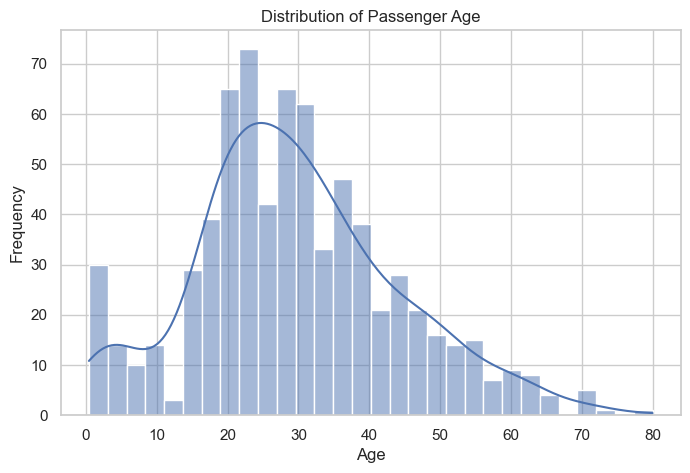

In [22]:
#Age Histogram
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=30, kde=True)

plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

### Observation

The age histogram shows the distribution of passenger ages.
Most observations are concentrated within the adult age range, while
fewer passengers are present at the extreme ages.

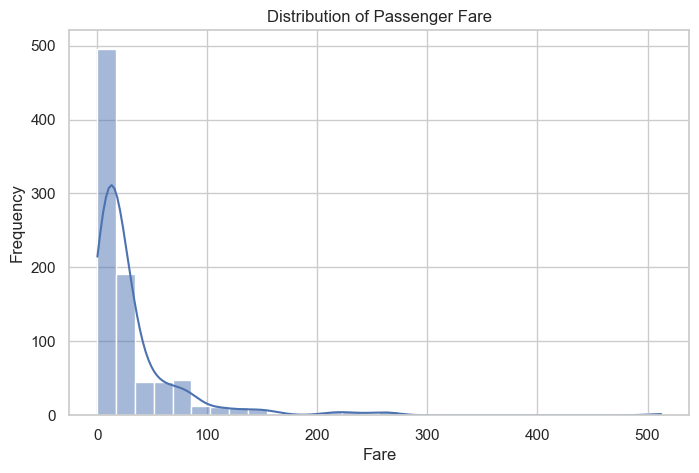

In [23]:
#Fare Histogram
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Fare", bins=30, kde=True)

plt.title("Distribution of Passenger Fare")
plt.xlabel("Fare")
plt.ylabel("Frequency")

plt.show()

### Observation

The fare distribution is right-skewed, with most passengers paying
relatively lower fares and a smaller number paying substantially higher fares.

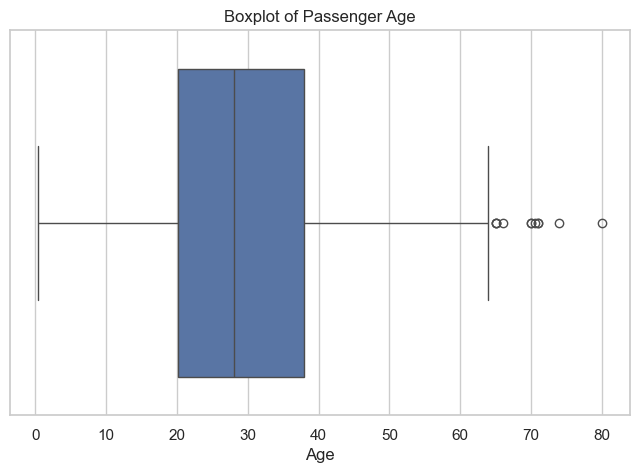

In [24]:
#Box Plot For Age
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Age")

plt.title("Boxplot of Passenger Age")
plt.xlabel("Age")

plt.show()

### Observation

The boxplot displays the median, quartiles and potential outliers
in passenger age.

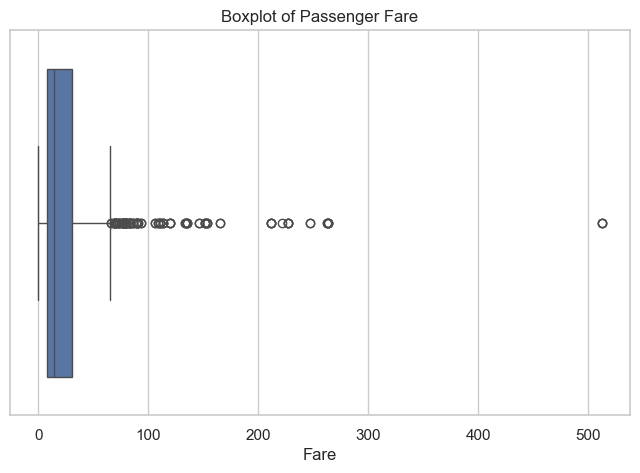

In [25]:
#Box plot for Fare
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Fare")

plt.title("Boxplot of Passenger Fare")
plt.xlabel("Fare")

plt.show()

### Observation

The fare boxplot shows several high-value observations, indicating
that the Fare variable contains extreme values and is strongly right-skewed.

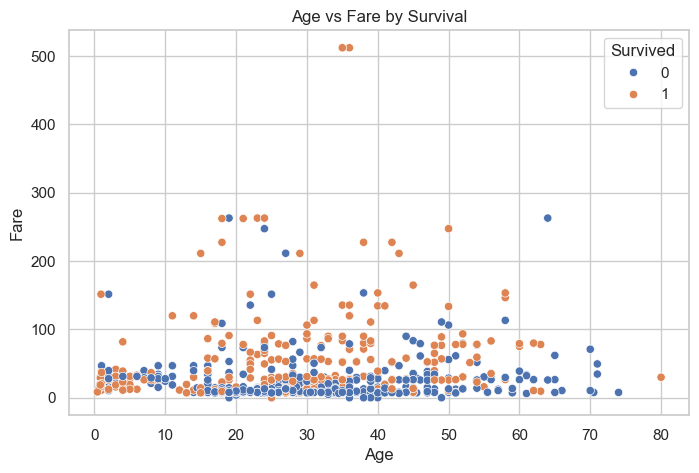

In [26]:
#Scatter Plot
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Age", y="Fare", hue="Survived")

plt.title("Age vs Fare by Survival")
plt.xlabel("Age")
plt.ylabel("Fare")

plt.show()

### Observation

The scatterplot shows the relationship between passenger age and fare.
There is no strong linear relationship between the two variables, although
some high-fare observations are visible.

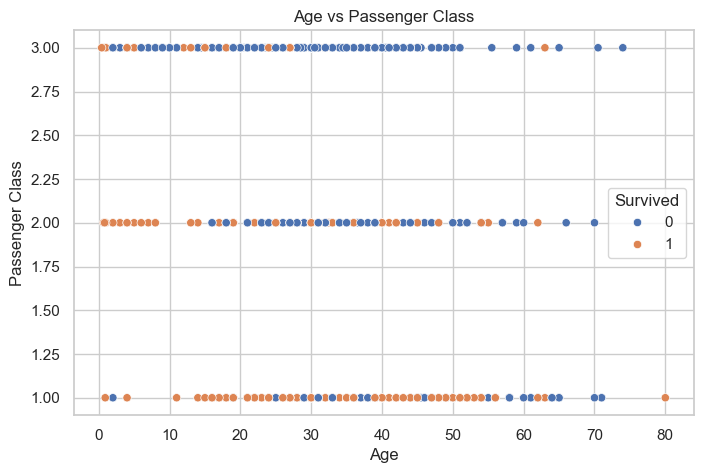

In [27]:
#Another Scatter Plot
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="Age", y="Pclass", hue="Survived")

plt.title("Age vs Passenger Class")
plt.xlabel("Age")
plt.ylabel("Passenger Class")

plt.show()

In [28]:
#Survival Rate By Class
df.groupby("Pclass")["Survived"].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

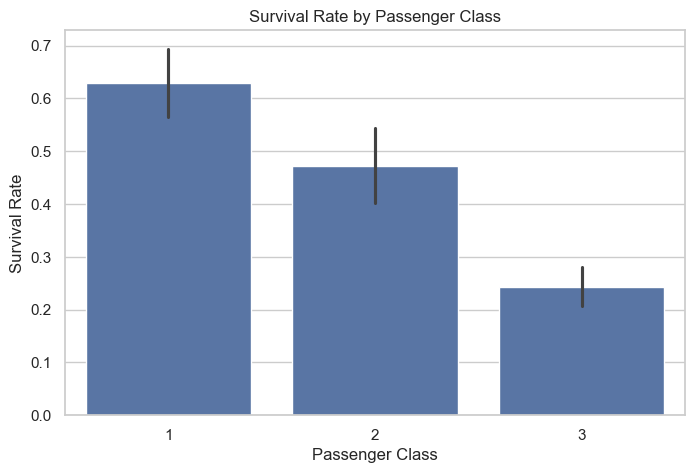

In [29]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="Pclass", y="Survived")

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()

### Observation

The survival rate differs across passenger classes.
Passenger class is therefore an important variable when examining
survival outcomes.

In [30]:
#Survival Rate By Gender
df.groupby("Sex")["Survived"].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

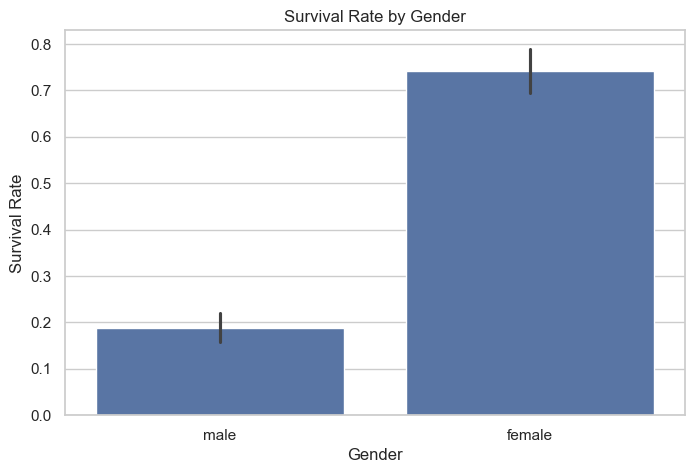

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x="Sex", y="Survived")

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")

plt.show()

### Observation

The survival rate differs considerably between genders, indicating
that gender is strongly associated with survival in the dataset.

In [32]:
#Creating a Correlation Matrix
numeric_df = df.select_dtypes(include=np.number)

In [33]:
correlation_matrix = numeric_df.corr()

correlation_matrix

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
PassengerId,1.000000,-0.005007,-0.035144,0.036847,-0.057527,-0.001652,0.012658
Survived,-0.005007,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
Pclass,-0.035144,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
Age,0.036847,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
SibSp,-0.057527,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
Parch,-0.001652,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
Fare,0.012658,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


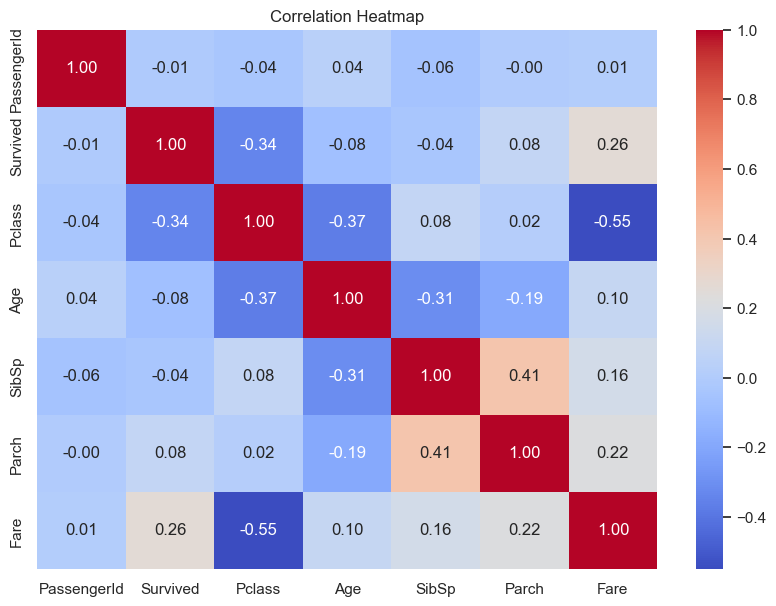

In [34]:
#Creating Heat Map
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

### Observation

The correlation heatmap displays the strength and direction of relationships
between numerical variables. Positive values indicate positive relationships,
while negative values indicate negative relationships.

In [35]:
#Pair Plot
pairplot_data = df[
    ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
].dropna()

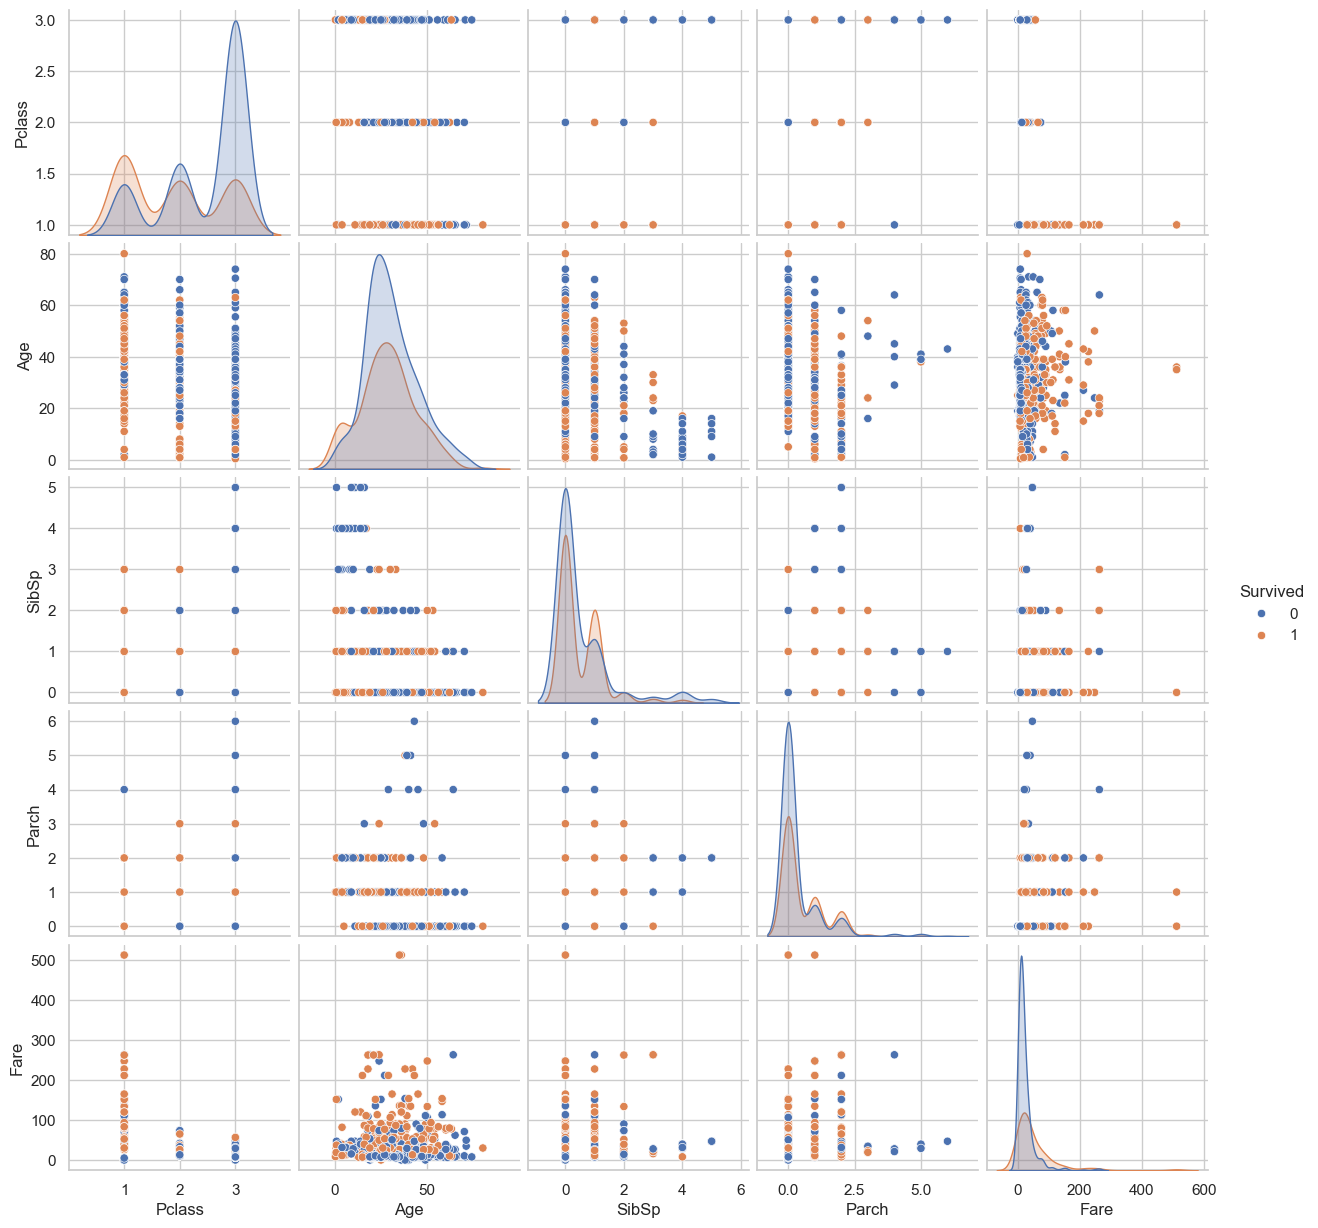

In [36]:
sns.pairplot(
    pairplot_data,
    hue="Survived"
)

plt.show()

### Observation

The pairplot allows multiple numerical variables to be examined simultaneously.
It helps identify distributions, relationships, clusters and possible outliers.
The survival categories also allow differences between survivors and
non-survivors to be visually compared.

In [37]:
#Checking Duplicates
df.duplicated().sum()

np.int64(0)

### Observation

The duplicate-value check was performed to determine whether the dataset
contains repeated records.

In [38]:
#Checking Unique Values
df.nunique()

PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3
dtype: int64

In [39]:
#Analyzing Embarked
df["Embarked"].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

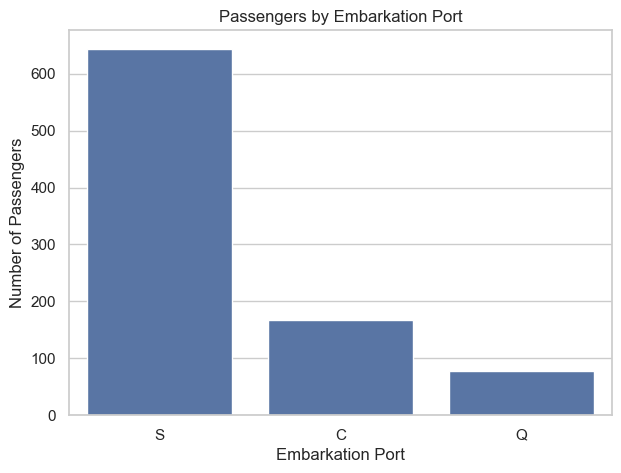

In [40]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Embarked")

plt.title("Passengers by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Number of Passengers")

plt.show()

In [41]:
#Analyzing Family Size
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

In [42]:
df[["SibSp", "Parch", "FamilySize"]].head()

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


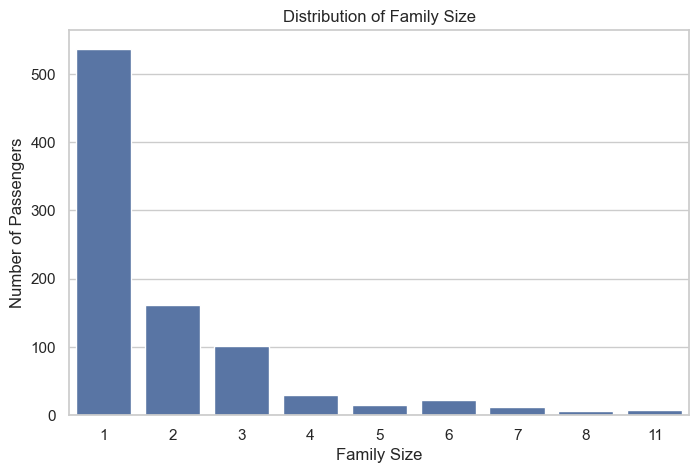

In [43]:
#Family Size Distribution
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="FamilySize")

plt.title("Distribution of Family Size")
plt.xlabel("Family Size")
plt.ylabel("Number of Passengers")

plt.show()

### Observation

Most passengers belonged to relatively small family groups.
Family size can be further investigated to understand its relationship
with survival.

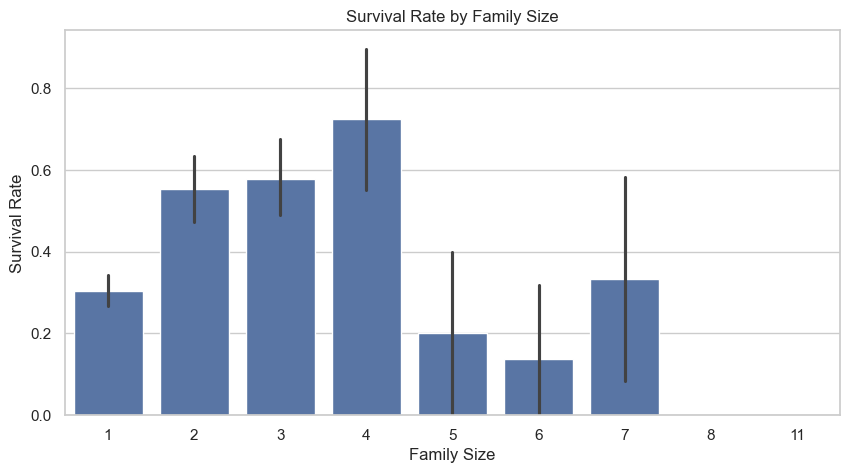

In [44]:
#Family Size vs Survival
plt.figure(figsize=(10, 5))

sns.barplot(data=df, x="FamilySize", y="Survived")

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate")

plt.show()

In [45]:
#Checking Skweness
df[["Age", "Fare"]].skew()

Age     0.389108
Fare    4.787317
dtype: float64

In [46]:
#Log Transformation Example
df["Log_Fare"] = np.log1p(df["Fare"])

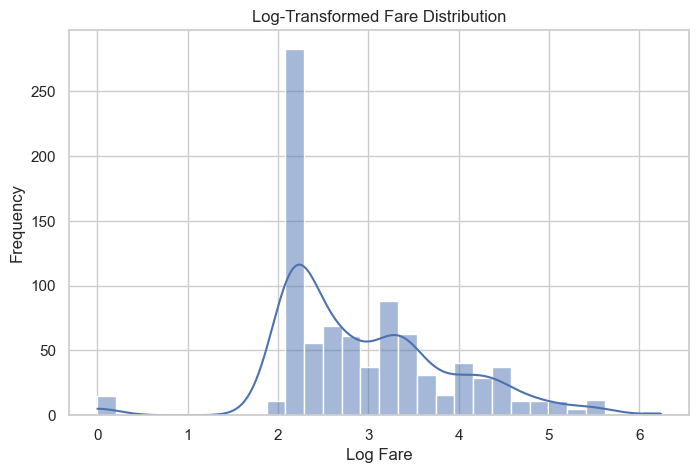

In [47]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Log_Fare", bins=30, kde=True)

plt.title("Log-Transformed Fare Distribution")
plt.xlabel("Log Fare")
plt.ylabel("Frequency")

plt.show()

### Observation

The log transformation reduces the effect of extremely large fare values
and makes the distribution more balanced.

# 6. Key Findings

1. The Titanic dataset contains passenger demographic, travel and survival information.

2. Missing values are present in some columns and require appropriate handling
   depending on the analysis.

3. Passenger age is distributed across children, adults and older passengers.

4. Fare is strongly right-skewed because a smaller number of passengers paid
   substantially higher fares.

5. Survival outcomes differ significantly by gender.

6. Passenger class is associated with survival outcomes.

7. The correlation heatmap helps identify relationships between numerical variables.

8. The pairplot provides a multivariate view of relationships and distributions.

9. Boxplots help identify potential outliers, particularly in Fare.

10. The analysis demonstrates how statistical summaries and visualizations
    can be used together to identify patterns, relationships and anomalies.

# 7. Conclusion

Exploratory Data Analysis was performed on the Titanic dataset using Python,
Pandas, Matplotlib and Seaborn.

Statistical techniques such as info(), describe(), value_counts() and
correlation analysis were used to understand the dataset.

Visual techniques including histograms, boxplots, scatterplots, pairplots
and heatmaps were used to identify distributions, relationships, trends
and potential anomalies.

The analysis indicates that variables such as gender and passenger class
have important relationships with survival. The analysis also identified
missing values and skewed distributions that should be considered during
data preprocessing and further analysis.

Overall, EDA provides a systematic way to understand the dataset before
performing further statistical analysis or machine learning.